# 03 · El ruido y las PSD

**Objetivo:** entender el ruido de gwsim:

- qué contiene el paquete de PSD;
- cómo son las ASD de H1, L1 y V1 en O3b frente a las curvas de diseño;
- cómo se generan muestras de solo ruido;
- comprobar que, tras el blanqueado, el ruido es aproximadamente gaussiano N(0, 1);
- y, sobre todo, en qué **no** se parece al ruido real.

**Requisitos:** tutoriales 01 y 02. El paquete de PSD es casi imprescindible aquí: sin él, solo se ven las curvas analíticas.

**Tiempo aproximado:** menos de 1 minuto en CPU.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == 'tutorials':
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

PSD_PACK = 'psd_pack_o3b.npz'
pack_path = Path(PSD_PACK) if Path(PSD_PACK).is_absolute() else ROOT / PSD_PACK
USE_PACK = pack_path.is_file()
if not USE_PACK:
    warnings.warn(f'No encuentro {pack_path}: uso ruido analítico (curvas de diseño), no las PSD de O3b.')

from gwsim.noise import PsdPackNoise, AnalyticNoise
O3B_GPS = [1256655618.0, 1269363618.0]
noise = PsdPackNoise(pack_path, ['train']) if USE_PACK else AnalyticNoise(O3B_GPS)
COLORS = {'H1': '#d55e00', 'L1': '#0072b2', 'V1': '#009e73'}
IFOS = ['H1', 'L1', 'V1']

from gwsim.recipe import Physics, RowOptions, simulate_row
phys = Physics()
cfg = phys.config

/afs/ciemat.es/user/v/vserrano/miniconda3/envs/gw-env/lib/python3.10/site-packages/pycbc/types/array.py:36: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal as _lal
/afs/ciemat.es/user/v/vserrano/miniconda3/envs/gw-env/lib/python3.10/site-packages/pycbc/waveform/plugin.py:99: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain

## 1. Qué contiene el paquete de PSD

El paquete es un `.npz` (un archivo de arrays de numpy). Contiene:

- `psd`: array `(bloques, 3, frecuencias)`. Es la PSD de Welch de cada bloque y detector, estimada con segmentos de 8 s solapados al 50 % sobre 128 s de datos públicos de O3b (GWOSC), **antes de interpolar**; Δf = 1/8 Hz, de 0 a 2048 Hz.
- `block_id`, `split`, `file_group_id`: identificador del bloque, su split (`train`/`val`/`cal`/`test`) y su **entorno**, el grupo de ficheros contiguos de O3b al que pertenece. Los splits no comparten entornos.
- La tabla de **recortes** (`crop_*`): para cada recorte, su bloque y su GPS central. Cada señal se asigna a un recorte, y su GPS es el de ese recorte.

gwsim interpola cada PSD a las dos rejillas de frecuencia que necesita (`docs/FISICA.md` §5).

In [2]:
if USE_PACK:
    with np.load(pack_path, allow_pickle=False) as data:
        for key in data.files:
            print(f'{key:<20} {str(data[key].shape):<18} {data[key].dtype}')
    splits, counts = np.unique(noise.block_split, return_counts=True)
    print('\nBloques por split:', dict(zip(splits, counts)))
    print('Entornos por split:', {s: len(np.unique(noise.block_group[noise.block_split == s])) for s in splits})
    print('Recortes del split train:', len(noise.crop_id))
else:
    print('Sin paquete de PSD: esta sección no tiene datos que mostrar.')

format_version       ()                 int64
detectors            (3,)               <U2
psd                  (292, 3, 16385)    float64
delta_f              (292,)             float64
block_id             (292,)             <U13
split                (292,)             <U5
file_group_id        (292,)             int64
psd_start            (292,)             float64
psd_end              (292,)             float64
crop_noise_crop_id   (4380,)            <U14
crop_block_id        (4380,)            <U13
crop_center_gps      (4380,)            float64
crop_split           (4380,)            <U5

Bloques por split: {np.str_('cal'): np.int64(39), np.str_('test'): np.int64(25), np.str_('train'): np.int64(200), np.str_('val'): np.int64(28)}
Entornos por split: {np.str_('cal'): 3, np.str_('test'): 3, np.str_('train'): 20, np.str_('val'): 3}
Recortes del split train: 3000


## 2. ASD de O3b frente a las curvas de diseño

La **ASD** (amplitude spectral density) es √S_n(f), en 1/√Hz. Cuanto más baja, más sensible es el detector a esa frecuencia. Comparamos tres bloques del paquete con las curvas analíticas de diseño que usa `noise.source = "analytic"`: aLIGOZeroDetHighPower para los LIGO y AdvVirgo para Virgo.

Fíjate en tres cosas:

- O3b es menos sensible que el diseño;
- hay líneas estrechas (red eléctrica de 60 Hz en EE. UU. y 50 Hz en Europa, modos violín hacia 500 Hz, calibración);
- los bloques no son idénticos entre sí: la PSD cambia con el tiempo.

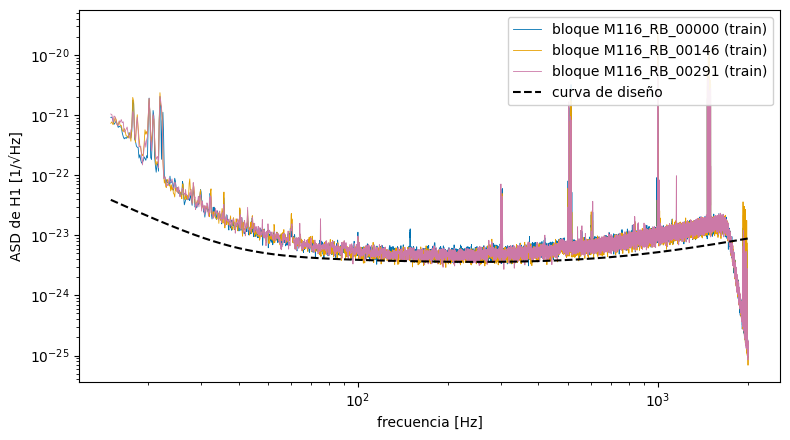

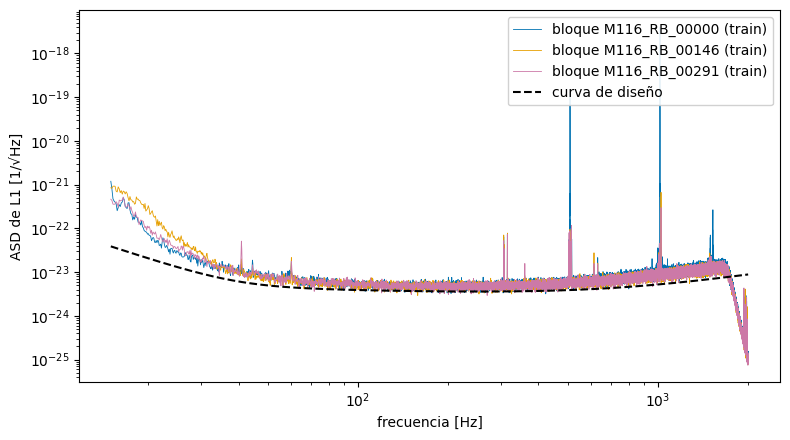

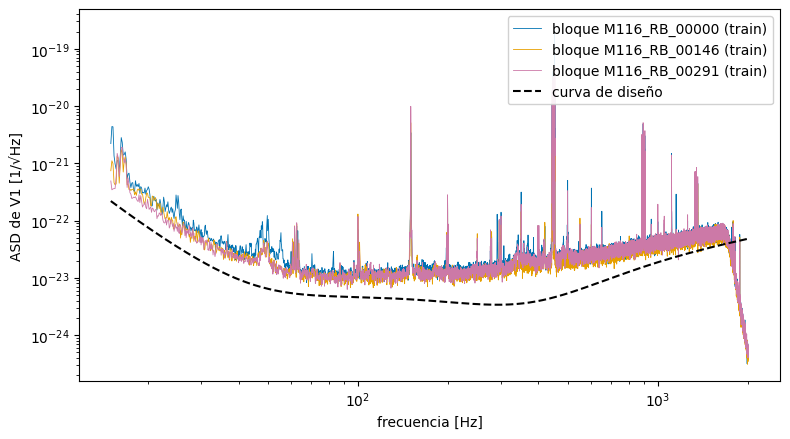

In [3]:
from pycbc.psd import aLIGOZeroDetHighPower, AdvVirgo
ANALYTIC = {'H1': aLIGOZeroDetHighPower, 'L1': aLIGOZeroDetHighPower, 'V1': AdvVirgo}
BLOCK_COLORS = ['#0072b2', '#e69f00', '#cc79a7']
if USE_PACK:
    picks = np.linspace(0, len(noise.block_id) - 1, 3).round().astype(int)
for j, ifo in enumerate(IFOS):
    fig, ax = plt.subplots(figsize=(8, 4.5))
    if USE_PACK:
        for c, k in zip(BLOCK_COLORS, picks):
            f = np.arange(noise.psd.shape[-1]) * noise.delta_f[k]
            keep = (f >= 15) & (f <= 2000)
            ax.loglog(f[keep], np.sqrt(noise.psd[k, j][keep]), color=c, lw=0.6,
                      label=f'bloque {noise.block_id[k]} ({noise.block_split[k]})')
    flen = 16385
    ana = ANALYTIC[ifo](flen, 0.125, 10.0)
    fa = ana.sample_frequencies.numpy()
    keep = (fa >= 15) & (fa <= 2000)
    ax.loglog(fa[keep], np.sqrt(ana.numpy()[keep]), color='k', lw=1.5, ls='--', label='curva de diseño')
    ax.set_xlabel('frecuencia [Hz]')
    ax.set_ylabel(f'ASD de {ifo} [1/√Hz]')
    ax.legend(loc='upper right', framealpha=0.9)
    plt.tight_layout()
    plt.show()

## 3. Muestras de solo ruido

En el modo `noise_only` no hay señal, pero el procesado es el mismo. Es lo que necesitas para estimar la distribución de un estadístico **bajo la hipótesis nula** (solo ruido).

El ruido se genera en el dominio de la frecuencia: cada coeficiente de Fourier es una gaussiana compleja de varianza proporcional a S_n(f), y una FFT inversa da la serie temporal (`pycbc.noise.gaussian.noise_from_psd`). `gaussian_seed` fija la realización.

Generamos 6 muestras con semillas distintas.

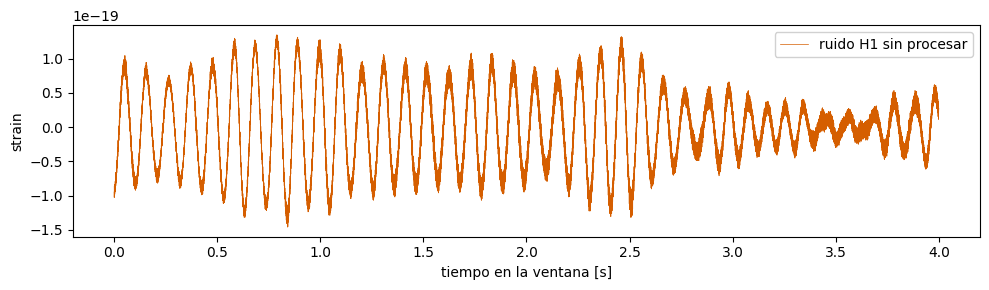

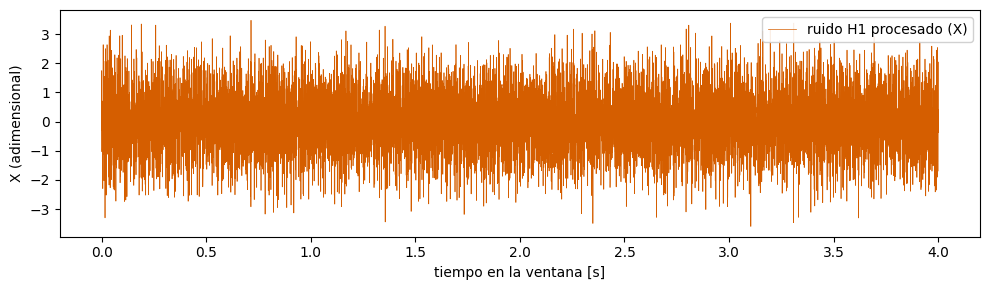

In [4]:
opts = RowOptions(physics=phys, mode='noise_only', outputs=('X', 'X_unnormalized', 'strain_noisy_raw'))
assignment = noise.assign(6, np.random.default_rng(5))
rows = []
for k in range(6):
    psds = noise.psds(assignment['block_id'][k], cfg)
    out, _ = simulate_row(None, assignment['gps'][k], psds, None, gaussian_seed=1000 + k, opts=opts)
    rows.append(out)
Xn = np.stack([r['X'] for r in rows])            # (6, 3, 16384)
t = np.arange(cfg.length) / cfg.sampling_frequency

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(t, rows[0]['strain_noisy_raw'][0], color=COLORS['H1'], lw=0.5, label='ruido H1 sin procesar')
ax.set_xlabel('tiempo en la ventana [s]')
ax.set_ylabel('strain')
ax.legend(loc='upper right', framealpha=0.9)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(t, Xn[0, 0], color=COLORS['H1'], lw=0.5, label='ruido H1 procesado (X)')
ax.set_xlabel('tiempo en la ventana [s]')
ax.set_ylabel('X (adimensional)')
ax.legend(loc='upper right', framealpha=0.9)
plt.tight_layout(); plt.show()

El ruido sin procesar está dominado por oscilaciones lentas: el muro sísmico de baja frecuencia, millones de veces más potente que el ruido en la banda útil. Tras blanquear y filtrar a 30–1024 Hz, se ve como un ruido «blanco» sin estructura aparente.

## 4. ¿Es el ruido blanqueado N(0, 1)?

Si el ruido es gaussiano y el blanqueado es correcto, cada canal de `X` debería tener una distribución N(0, 1), un espectro plano dentro de la banda y casi ninguna correlación entre muestras separadas. Lo comprobamos de tres formas.

### 4a. Histograma

Las curvas punteadas son la densidad N(0, 1). La escala logarítmica en el eje vertical deja ver las colas, que es donde se notaría una desviación de la gaussianidad (por ejemplo, glitches).

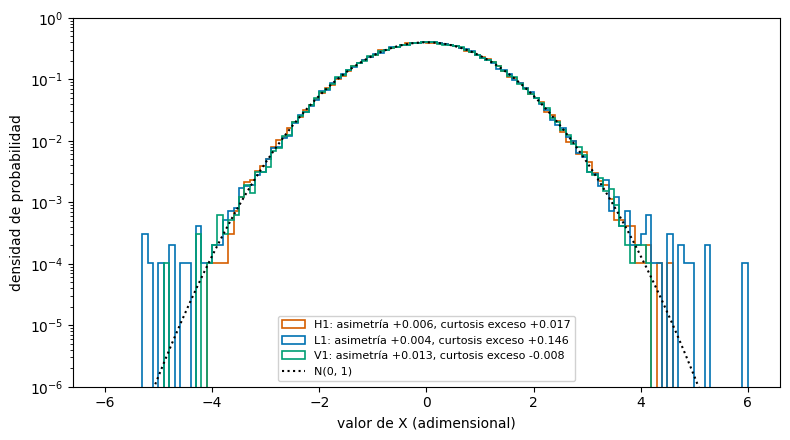

In [5]:
from scipy import stats
bins = np.linspace(-6, 6, 121)
x_pdf = np.linspace(-6, 6, 400)
fig, ax = plt.subplots(figsize=(8, 4.5))
for j, ifo in enumerate(IFOS):
    v = Xn[:, j].ravel()
    ax.hist(v, bins=bins, density=True, histtype='step', color=COLORS[ifo], lw=1.2,
            label=f'{ifo}: asimetría {stats.skew(v):+.3f}, curtosis exceso {stats.kurtosis(v):+.3f}')
ax.plot(x_pdf, stats.norm.pdf(x_pdf), color='k', ls=':', lw=1.5, label='N(0, 1)')
ax.set_yscale('log')
ax.set_ylim(1e-6, 1)
ax.set_xlabel('valor de X (adimensional)')
ax.set_ylabel('densidad de probabilidad')
ax.legend(loc='lower center', framealpha=0.9, fontsize=8)
plt.tight_layout(); plt.show()

La asimetría y la curtosis en exceso deben ser cercanas a 0 (los valores de una gaussiana); con 6 × 16384 muestras por detector, las fluctuaciones son de unas centésimas.

### 4b. ASD del ruido blanqueado

Estimamos la PSD de `X` con el método de Welch (`scipy.signal.welch`, segmentos de 1 s). Dentro de la banda de 30–1024 Hz debe ser **plana**: eso significa «blanqueado». Fuera de la banda cae, porque los filtros paso alto y paso bajo la eliminan.

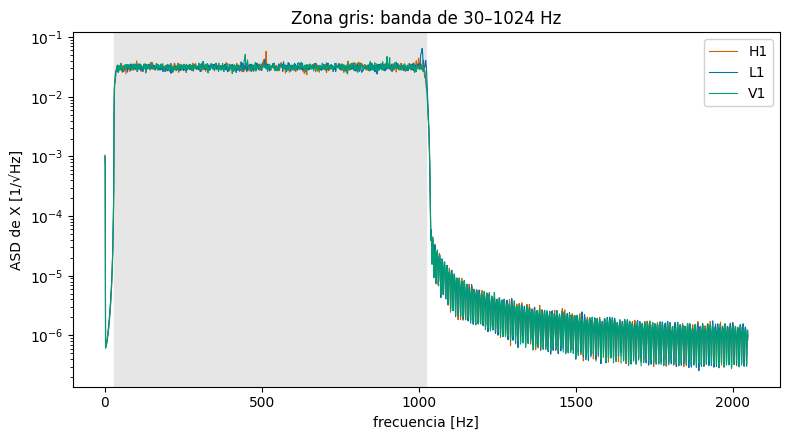

In [6]:
from scipy.signal import welch
fig, ax = plt.subplots(figsize=(8, 4.5))
for j, ifo in enumerate(IFOS):
    f, p = welch(Xn[:, j], fs=cfg.sampling_frequency, nperseg=int(cfg.sampling_frequency))
    ax.semilogy(f, np.sqrt(p.mean(axis=0)), color=COLORS[ifo], lw=0.8, label=ifo)
ax.axvspan(30, 1024, color='0.9', zorder=0)
ax.set_xlabel('frecuencia [Hz]')
ax.set_ylabel('ASD de X [1/√Hz]')
ax.set_title('Zona gris: banda de 30–1024 Hz')
ax.legend(loc='upper right', framealpha=0.9)
plt.tight_layout(); plt.show()

### 4c. Autocorrelación

Un ruido blanco *ideal* no tendría ninguna correlación entre muestras distintas. El nuestro es blanco **solo dentro de la banda**, y un ruido plano entre f₁ = 30 Hz y f₂ = 1024 Hz tiene autocorrelación

R(τ) = [sen(2π f₂ τ) − sen(2π f₁ τ)] / [2π (f₂ − f₁) τ],

una oscilación amortiguada que cae a casi cero en pocos milisegundos. La comparamos con la medida (las diferencias pequeñas vienen de que los bordes de los filtros reales no son verticales).

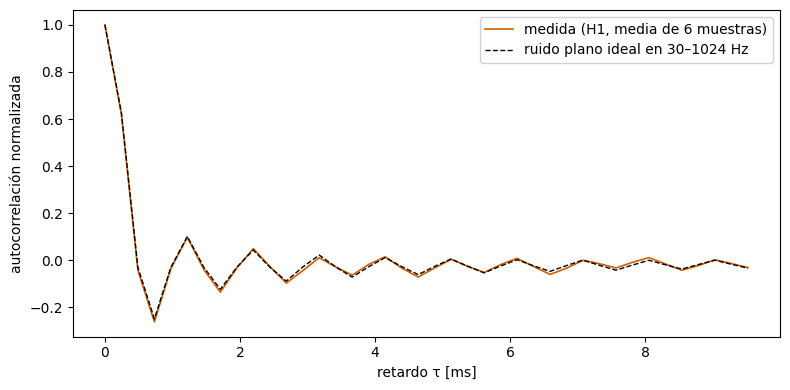

In [7]:
def autocorrelation(x):
    x = x - x.mean()
    n = len(x)
    spec = np.fft.rfft(x, 2 * n)
    r = np.fft.irfft(np.abs(spec) ** 2, 2 * n)[:n]
    return r / r[0]

max_lag = int(0.01 * cfg.sampling_frequency)            # 10 ms
tau = np.arange(max_lag) / cfg.sampling_frequency
r = np.mean([autocorrelation(Xn[k, 0]) for k in range(len(Xn))], axis=0)[:max_lag]
f1, f2 = 30.0, 1024.0
with np.errstate(invalid='ignore', divide='ignore'):
    theory = (np.sin(2 * np.pi * f2 * tau) - np.sin(2 * np.pi * f1 * tau)) / (2 * np.pi * (f2 - f1) * tau)
theory[0] = 1.0
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(1e3 * tau, r, color=COLORS['H1'], lw=1.2, label='medida (H1, media de 6 muestras)')
ax.plot(1e3 * tau, theory, color='k', ls='--', lw=1, label='ruido plano ideal en 30–1024 Hz')
ax.set_xlabel('retardo τ [ms]')
ax.set_ylabel('autocorrelación normalizada')
ax.legend(loc='upper right', framealpha=0.9)
plt.tight_layout(); plt.show()

Consecuencia práctica: las 16384 muestras de un canal **no** son independientes entre sí. Si un estadístico trata cada muestra como independiente (por ejemplo, para calcular un p-valor), se equivocará. Las muestras separadas por más de unos milisegundos sí son casi independientes.

## 5. Por qué este ruido no es ruido real

Todo lo anterior sale «perfecto» porque el ruido de gwsim es, por construcción, **gaussiano y estacionario**: una sola PSD fija por muestra, con fases aleatorias. El ruido real de los detectores no lo es:

- **Glitches:** transitorios no gaussianos de origen instrumental o ambiental (*blips*, *scattered light*, *tomtes*, *whistles*…), con tasas de varios por minuto en O3. Algunos se parecen mucho a señales de masas altas. En el histograma de §4a aparecerían como colas mucho más pesadas que la gaussiana.
- **No estacionariedad:** la PSD real cambia en escalas de minutos a horas (el tráfico, el viento, el mar). Aquí cada muestra usa la PSD fija de su bloque.
- **Líneas y artefactos variables**, y huecos en los datos.

Para un estudio basado en rangos y agnóstico al modelo, la consecuencia es directa: la distribución nula que estimes con muestras `noise_only` de gwsim describe el fondo **gaussiano**. Con ruido real, la cola de falsas alarmas será más pesada. Ver `docs/VALIDEZ.md`.

**Siguiente:** `04_priors_y_configuracion.ipynb`.